# Notebook 1 · Deep learning: benign vs malignant mammograms

The project has three files:

| File | Content |
|---|---|
| **`1_deep_learning.ipynb`**  | Find the data, split it, train the ResNet18 model, evaluate it |
| `2_classical_ml.ipynb` | Baseline, SVM and Random Forest, then compare all models |
| `3_flask_app` | A web page where you upload a mammogram and see the prediction |

Steps in this notebook, built one at a time:

| Step | What we do |
|---|---|
| 1 | Find and inspect the images |
| **2** | **Split into train / validation / test** |
| 3 | Train the deep learning model (transfer learning) |
| 4 | Evaluate it on the test set |

## Step 1 · Find and inspect the images

**What:** scan the `images` folder and build a table with one row per mammogram (file path, label, patient, view).
**Why:** every later step needs this table, and we must be sure we only use real mammograms. The folders also contain mask files, overlay files and metadata that are *not* training images.

In [12]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
IMAGES_DIR = Path("MINI-DDSM-Complete-JPEG-8")    # the folder containing Benign/ and Cancer/
print("Looking in:", IMAGES_DIR.resolve())
print("Folder exists:", IMAGES_DIR.exists())

Looking in: D:\BS CS AI\5th Semester\Machine Learning\Project\MINI-DDSM-Complete-JPEG-8
Folder exists: True


**Build the table.** We keep only `.jpg` files inside a `Benign` or `Cancer` folder, and skip anything with `Mask` in its name (those are outlines of the tumour, drawn after diagnosis, so using them would leak data).

In [14]:
rows = []
for p in sorted(IMAGES_DIR.rglob("*.jpg")):
    if "mask" in p.name.lower():
        continue                              # skip tumour-outline masks
    folder = p.parent.parent.name             # Benign, Cancer or Normal
    if folder not in ["Benign", "Cancer"]:
        continue                              # skip Normal/
    rows.append({
        "path": p.as_posix(),
        "label": 0 if folder == "Benign" else 1,     # 0 = benign, 1 = cancer
        "class_name": folder,
        "patient": folder + "_" + p.parent.name,     # e.g. Benign_0029
        "view": p.stem.split(".")[-1],               # e.g. LEFT_CC
    })

df = pd.DataFrame(rows)
print(f"{len(df)} images found")
print(df.class_name.value_counts())   # count of each class
df.head()

5400 images found
class_name
Cancer    2716
Benign    2684
Name: count, dtype: int64


,path,label,class_name,patient,view
0,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,LEFT_CC
1,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,LEFT_MLO
2,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,RIGHT_CC
3,MINI-DDSM-Complete-JPEG-8/Benign/0029/C_0029_1...,0,Benign,Benign_0029,RIGHT_MLO
4,MINI-DDSM-Complete-JPEG-8/Benign/0033/C_0033_1...,0,Benign,Benign_0033,LEFT_CC


Expected: 2,684 Benign and 2,716 Cancer images.

In [15]:
print(df.groupby("class_name").agg(images=("path", "size"), patients=("patient", "nunique")))
print()
print("Images per patient:")
print(df.groupby("patient").size().value_counts().sort_index())

            images  patients
class_name                  
Benign        2684       671
Cancer        2716       679

Images per patient:
4    1350
Name: count, dtype: int64


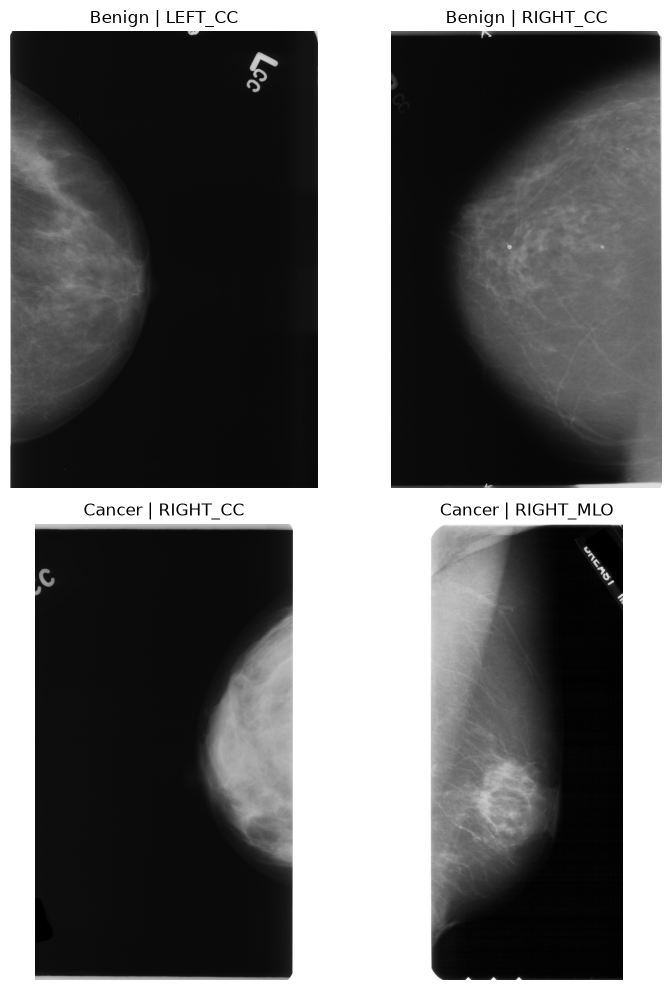

In [16]:
# 2 random benign and 2 random cancer images
samples = pd.concat([df[df.label == 0].sample(2, random_state=SEED),
                     df[df.label == 1].sample(2, random_state=SEED)])

fig, axes = plt.subplots(2, 2, figsize=(8, 10))
for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    ax.imshow(Image.open(row.path).convert("L"), cmap="gray")
    ax.set_title(f"{row.class_name} | {row.view}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Check image sizes.** Neural networks need every image to be the same size, so we will resize them.

In [17]:
sample = df.sample(200, random_state=SEED)
sizes = [Image.open(p).size for p in sample.path]
widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]
print(f"width : {min(widths)} to {max(widths)} pixels")
print(f"height: {min(heights)} to {max(heights)} pixels")

width : 916 to 2521 pixels
height: 1981 to 3436 pixels


## Step 2 · Split into train / validation / test

**What:** divide the data into three groups, 80% / 10% / 10%.

| Group | Used for |
|---|---|
| **train** | the model learns from these images |
| **validation** | during training: decide when to stop, and later choose the decision threshold |
| **test** | the final exam: used **once**, at the very end, to report honest results |


**Why we split by *patient*, not by image:** one patient has up to 4 images (left/right breast, CC/MLO view) that look alike. If we split by image, the left breast of a patient could be in training and the right breast in the test set. The model would then partly recognise the *patient*, not the disease, and the test score would look better than it really is. So all images of one patient go to the same group.

**How:** split the list of patients (keeping the benign/cancer ratio equal in each group), then give every image the group of its patient. The seed is fixed so the split is the same every time.

In [18]:
from sklearn.model_selection import train_test_split

# one row per patient with its label
patients = df.groupby("patient").label.first().reset_index()

# 10% of the patients go to test
trainval, test = train_test_split(patients, test_size=0.10, stratify=patients.label, random_state=SEED)

# 10% of all patients go to validation (that is 1/9 of the patients left)
train, val = train_test_split(trainval, test_size=1/9, stratify=trainval.label, random_state=SEED)

# every image gets the group of its patient
df["split"] = "train"
df.loc[df.patient.isin(val.patient), "split"] = "val"
df.loc[df.patient.isin(test.patient), "split"] = "test"

**Check the split.** Sizes should be close to 80/10/10 and the Benign/Cancer mix similar in every group. The last line proves no patient is in two groups.

In [19]:
groups = ["train", "val", "test"]

print("Images per group and class:")
print(df.groupby(["split", "class_name"]).size().unstack().loc[groups])
print()
print("Share of images in each group (%):")
print((df.split.value_counts(normalize=True).loc[groups] * 100).round(1))
print()
# must be 0: no patient may be in two groups
print("Patients in more than one group:", (df.groupby("patient").split.nunique() > 1).sum())

Images per group and class:
class_name  Benign  Cancer
split                     
train         2148    2172
val            268     272
test           268     272

Share of images in each group (%):
split
train    80.0
val      10.0
test     10.0
Name: proportion, dtype: float64

Patients in more than one group: 0


**Save the split.** The classical ML notebook and the Flask app must use exactly the same train/validation/test groups, so we save them to a file.

In [20]:
df.to_csv("data_split.csv", index=False)
print("Saved data_split.csv with", len(df), "rows")

Saved data_split.csv with 5400 rows


## Step 3 · Train the deep learning model

We use ResNet18, a neural network that is already trained on millions of normal photos. We keep what it learned and train only a new last layer for benign vs cancer. This is called transfer learning.

Parts: 3.1 resize the images, 3.2 load them for training, 3.3 build the model, 3.4 train it, 3.5 save it.

### 3.1 Resize all images and save them in one file

The original images are huge (about 2000 x 3000 pixels). We resize all of them once to 224 x 224 grey images and save them in one file, so training does not have to open 5,400 big JPEG files every time. Row i in this file is row i in `data_split.csv`.

In [21]:
import numpy as np

IMG_SIZE = 224

def load_image(path):
    img = Image.open(path)
    img.draft("L", (IMG_SIZE, IMG_SIZE))              # makes loading big JPEGs faster
    img = img.convert("L").resize((IMG_SIZE, IMG_SIZE))
    return np.array(img)

images = np.zeros((len(df), IMG_SIZE, IMG_SIZE), dtype=np.uint8)
for i, path in enumerate(df.path):
    images[i] = load_image(path)
    if i % 500 == 0:
        print(i, "of", len(df))

np.save("images_224.npy", images)
print("Saved images_224.npy with shape", images.shape)

0 of 5400
500 of 5400
1000 of 5400
1500 of 5400
2000 of 5400
2500 of 5400
3000 of 5400
3500 of 5400
4000 of 5400
4500 of 5400
5000 of 5400
Saved images_224.npy with shape (5400, 224, 224)


Check that the first resized image looks right.

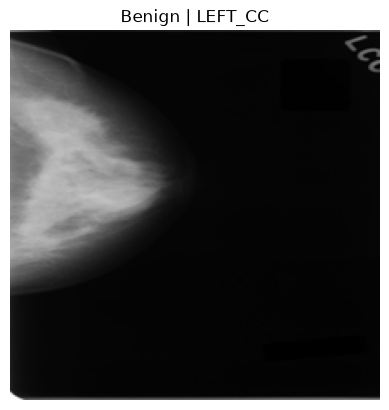

In [22]:
plt.imshow(images[0], cmap="gray")
plt.title(df.class_name[0] + " | " + df.view[0])
plt.axis("off")
plt.show()